# 00 · Quick start

Daedalus computes the stationary statistics of a stochastic dynamical system (mean, two-point function, higher cumulants) as a **loop expansion** around the mean-field solution. You write the model as stochastic differential equations; Daedalus derives the Martin–Siggia–Rose–Janssen–De Dominicis (MSRJD) action, enumerates the Feynman diagrams and evaluates every time integral exactly.

This notebook goes once through the whole workflow:

1. declare an SDE,
2. compute its two-point function at tree level and with one- and two-loop corrections,
3. compare with an independent simulation and with the exact stationary variance.

Model: a particle in a quartic potential with white noise,

$$\dot x = -\mu x - \varepsilon x^3 + \xi(t), \qquad \langle \xi(t)\xi(t')\rangle = 2D\,\delta(t-t').$$

Run time: under a minute.

In [1]:
%matplotlib inline
try:
    preparser(False)   # Sage kernel: plain Python syntax and numbers in the cells below
except NameError:
    pass
import os, sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt
# locate the repository root (the folder holding the 'api' package) from any working directory
_root = os.path.abspath('')
while _root != os.path.dirname(_root) and not os.path.isdir(os.path.join(_root, 'api')):
    _root = os.path.dirname(_root)
sys.path.insert(0, _root)
os.chdir(_root)
def ells(r):   # C(tau) per loop order (real parts), a list indexed by the loop order
    return [np.real(np.asarray(r['C_tau_by_ell'][l])) for l in sorted(r['C_tau_by_ell'])]
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Declare the model

`SDE` is a builder: each call adds one ingredient and returns the builder. `.drift(field, f)` is $\dot x = f$; `.noise(name, source, couples={field: c})` adds $c\,\mathrm{d}\eta$ to the equation of `field`, with the noise source taken from the noise library (`api.noise`, tutorial 02). `show()` prints the action and the mean-field equation Daedalus derived.

In [2]:
from api.sde import SDE
from api.noise import Gaussian
from api import compute_cumulants

ou = (SDE('quartic OU')
      .parameter('mu',  default=1.0,  domain='positive')
      .parameter('eps', default=0.05, domain='positive')
      .parameter('D',   default=1.0,  domain='positive')
      .field('x')
      .drift('x', '-mu*x - eps*x^3')
      .noise('xi', Gaussian(var='2*D'), couples={'x': 1}))
ou.show();

# SDE 'quartic OU' (ito)
.set_action_text('''
sum(
    xt[i]*(Dt*x[i] - (-mu*x[i] - eps*x[i]^3))
    - (D*xt[i]^2)
    for i in pop)
''')
.equation(lhs='Dt*x[i] + mu*x[i]', rhs='-eps*x[i]^3', population='pop')
# note: mean-field equation of 'x': linear term -mu*x[i] moved to the lhs.


The response field of `x` is `xt` ($\tilde x$). The term `-D*xt^2` is the Gaussian source: $-\tfrac12\,\mathrm{Var}\,\tilde x^2$ with variance rate $2D$. The mean-field equation $\mu x^* + \varepsilon x^{*3} = 0$ has the stable root $x^* = 0$.

## 2. Compute the two-point function

`compute_cumulants` takes the built model (`ou.build()`), the number of external legs `k`, the highest loop order `max_ell` and the external fields. A leg is `(field, index)`; `('x', 1)` is the fluctuation of `x` about the mean-field value (the name `'dx'` is accepted too). The result holds $C(\tau) = \kappa(x(t), x(t+\tau))$ on the lag grid, total and per loop order.

In [3]:
tau = np.linspace(-5, 5, 41)
t0 = time.time()
res = compute_cumulants(ou.build(), k=2, max_ell=2,
                        external_fields=[('x', 1), ('x', 1)],
                        tau_grid=tau, parallel=False, verbose=False)
print(f"status {res['status']}, {time.time() - t0:.1f} s")
by_ell = ells(res)
i0 = len(tau) // 2                                   # tau = 0
for ell, c in enumerate(by_ell):
    print(f"loop order {ell}: C(0) contribution {c[i0]:+.5f}")
print(f"total C(0) = {np.real(res['C_tau'][i0]):.5f}")

status ok, 0.7 s
loop order 0: C(0) contribution +1.00000
loop order 1: C(0) contribution -0.15000
loop order 2: C(0) contribution +0.06000
total C(0) = 0.91000


The tree level is the linear (Ornstein–Uhlenbeck) answer $D/\mu = 1$. The cubic force lowers the variance, and that reduction is entirely a loop effect: $-3\varepsilon D^2/\mu^3 = -0.15$ at one loop and $+24\varepsilon^2 D^3/\mu^5 = +0.06$ at two loops, the exact coefficients of the small-$\varepsilon$ expansion of the stationary variance.

## 3. Check: simulation and the exact variance

For a gradient system the stationary density is $p(x)\propto e^{-U(x)/D}$ with $U = \mu x^2/2 + \varepsilon x^4/4$, so the exact variance is a one-dimensional integral. `SDE.simulate` integrates the same model by Euler–Maruyama (an independent code path: it never sees the diagrams).

In [4]:
from scipy.integrate import quad
mu, eps, D = 1.0, 0.05, 1.0
U = lambda x: mu * x**2 / 2 + eps * x**4 / 4
Z = quad(lambda x: np.exp(-U(x) / D), -np.inf, np.inf)[0]
var_exact = quad(lambda x: x**2 * np.exp(-U(x) / D), -np.inf, np.inf)[0] / Z

t0 = time.time()
rec = ou.simulate(T=400.0, dt=0.01, n_paths=500, burn_in=10.0, bin=0.05, seed=1)
x = rec['fields']['x'][:, 0, :]                      # (time bins, paths)
x = x - x.mean()
lags = np.arange(0, 101, 5)                          # lag in bins of 0.05
cov = np.array([np.mean(x[:len(x) - l] * x[l:]) for l in lags])
# standard error from 20 batches of paths
batches = np.array_split(np.arange(x.shape[1]), 20)
cb = np.array([[np.mean(x[:len(x) - l, b] * x[l:, b]) for l in lags] for b in batches])
se = cb.std(0, ddof=1) / np.sqrt(len(batches))
print(f"simulation {time.time() - t0:.0f} s; Var: exact {var_exact:.4f}, "
      f"simulated {cov[0]:.4f} +- {se[0]:.4f}, tree {by_ell[0][i0]:.4f}, "
      f"1-loop {by_ell[0][i0] + by_ell[1][i0]:.4f}, 2-loop {np.real(res['C_tau'][i0]):.4f}")

simulation 1 s; Var: exact 0.8887, simulated 0.8919 +- 0.0021, tree 1.0000, 1-loop 0.8500, 2-loop 0.9100


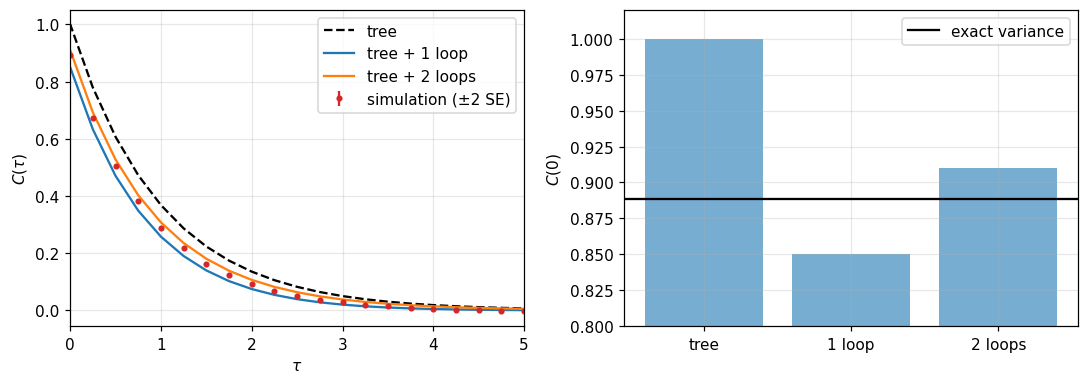

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(tau, by_ell[0], 'k--', label='tree')
ax[0].plot(tau, by_ell[0] + by_ell[1], label='tree + 1 loop')
ax[0].plot(tau, np.real(res['C_tau']), label='tree + 2 loops')
ax[0].errorbar(lags * rec['bin'], cov, yerr=2 * se, fmt='o', ms=3, color='C3', label='simulation (±2 SE)')
ax[0].set_xlim(0, 5); ax[0].set_xlabel(r'$\tau$'); ax[0].set_ylabel(r'$C(\tau)$'); ax[0].legend()
ax[1].bar(['tree', '1 loop', '2 loops'],
          [by_ell[0][i0], by_ell[0][i0] + by_ell[1][i0], np.real(res['C_tau'][i0])], color='C0', alpha=0.6)
ax[1].axhline(var_exact, color='k', label='exact variance')
ax[1].set_ylim(0.8, 1.02); ax[1].set_ylabel(r'$C(0)$'); ax[1].legend()
plt.tight_layout(); plt.show()

The loop expansion is an expansion in $g = \varepsilon D/\mu^2$ (here 0.05). Its terms alternate in sign: one loop overshoots the exact variance from below and two loops come back from above, with the error shrinking at each order (0.111, then 0.039, then 0.021 here); at smaller $g$ the convergence is much faster. Like most perturbation series this one is asymptotic, so the useful number of orders shrinks as $g$ grows. The simulation sits slightly above the exact value because of the Euler step ($\approx \mu\,\mathrm{d}t/2$ relative).

## Where next

| Tutorial | Topic |
|---|---|
| [01 · The SDE front end](01_sde_front_end.ipynb) | fields, populations, functions, kernels, interpretation |
| [02 · The noise library](02_noise_library.ipynb) | every noise source, jump law and composite; a Lévy-driven OU process |
| [03 · Point processes](03_point_processes.ipynb) | `.point_process`, Hawkes processes, the simulator |
| [04 · Delays](04_delays.ipynb) | hard and distributed delays, Padé loops |
| [05 · Outputs](05_outputs.ipynb) | cumulant objects, spectra, kernel integrals, $k = 3$, symbolic and transient outputs |
| [06 · Writing the action by hand](06_actions_by_hand.ipynb) | `TemporalModelBuilder` and how the SDE builder maps onto it |
| [07 · Spatial models](07_spatial.ipynb) | stochastic PDEs |